# 11 · Causal DNN frame classifier

Train a compact neural network to estimate the four bootstrap HMM states from normalized log-Mel features.

**Input:** notebook-10 aligned manifests and arrays  
**Output:** a reproducible checkpoint, training history, validation metrics, causality QA, and review candidates

This is an **exploratory bootstrap model**. Its targets come from energy VAD and uniform state division; high frame accuracy measures agreement with those pseudo-labels, not phonetic truth or production wake-word performance. The test partition remains untouched.

## 1. Reproducible runtime and frozen partitions

In [1]:
from pathlib import Path
import copy, json, random
import numpy as np
import matplotlib.pyplot as plt
from IPython import get_ipython
from IPython.display import Audio
import torch
from torch import nn
from torch.utils.data import DataLoader,TensorDataset
get_ipython().run_line_magic("matplotlib","inline")

root=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/"configs/preprocessing.json").exists())
cfg=json.loads((root/"configs/preprocessing.json").read_text())
out=root/"data/processed"/cfg["run_name"]; reports=root/"reports/preprocessing"/cfg["run_name"]
model_dir=out/"11_dnn"; model_dir.mkdir(parents=True,exist_ok=True)
rows=[json.loads(line) for line in (out/"10_bootstrap_aligned.jsonl").read_text().splitlines()]
topology=json.loads((out/"10_alignments/hmm_topology.json").read_text()); states=topology["states"]

In [2]:
seed=20261017
random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
torch.use_deterministic_algorithms(True)
device=torch.device("mps" if torch.backends.mps.is_available() else "cpu")
train_rows=[r for r in rows if r["split"]=="train"]
validation_rows=[r for r in rows if r["split"]=="validation" and not r["is_augmented"]]
assert not [r for r in train_rows if r["split"]=="test"]
print({"torch":torch.__version__,"device":str(device),"training_rows":len(train_rows),
       "validation_originals":len(validation_rows),"test_evaluated":False})

{'torch': '2.14.1', 'device': 'mps', 'training_rows': 12714, 'validation_originals': 797, 'test_evaluated': False}


## 2. Create a manual alignment-review queue

Training can run reproducibly, but a person must still listen to boundary candidates. The queue emphasizes short, long, quiet, and flagged positive training recordings. Its status remains `pending_manual_review`; the notebook never claims that playback equals a completed audit.

In [3]:
positive=[r for r in train_rows if r["is_keyword"] and not r["is_augmented"]]
by_duration=sorted(positive,key=lambda r:(r["speech_end_frame"]-r["speech_start_frame"],r["id"]))
by_level=sorted(positive,key=lambda r:(r["rms_dbfs"],r["id"]))
flagged=[r for r in positive if r["flags"]]
candidates=by_duration[:4]+by_duration[-4:]+by_level[:4]+flagged[:4]
review=[]
for row in candidates:
    if row["id"] not in {item["id"] for item in review}: review.append(row)
review=[{"id":r["id"],"audio_path":r["audio_path"],"rms_dbfs":r["rms_dbfs"],"flags":r["flags"],
         "start_frame":r["speech_start_frame"],"end_frame":r["speech_end_frame"],"status":"pending_manual_review"} for r in review]
(model_dir/"alignment_review_candidates.json").write_text(json.dumps(review,indent=2)+"\n")
display(review)

[{'id': 'stop__e96a5020_nohash_0',
  'audio_path': 'data/processed/baseline_v1/05_standardized/train/stop__e96a5020_nohash_0.wav',
  'rms_dbfs': -89.01572578078611,
  'flags': ['low_level_review'],
  'start_frame': 27,
  'end_frame': 35,
  'status': 'pending_manual_review'},
 {'id': 'stop__c6a23ff5_nohash_0',
  'audio_path': 'data/processed/baseline_v1/05_standardized/train/stop__c6a23ff5_nohash_0.wav',
  'rms_dbfs': -36.4822886824396,
  'flags': [],
  'start_frame': 9,
  'end_frame': 19,
  'status': 'pending_manual_review'},
 {'id': 'stop__3d3ddaf8_nohash_0',
  'audio_path': 'data/processed/baseline_v1/05_standardized/train/stop__3d3ddaf8_nohash_0.wav',
  'rms_dbfs': -27.650536772459134,
  'flags': [],
  'start_frame': 78,
  'end_frame': 92,
  'status': 'pending_manual_review'},
 {'id': 'stop__3d3ddaf8_nohash_1',
  'audio_path': 'data/processed/baseline_v1/05_standardized/train/stop__3d3ddaf8_nohash_1.wav',
  'rms_dbfs': -27.51986835106355,
  'flags': ['shorter_than_one_second'],
  's

In [4]:
review_example=review[0]
print("Review candidate:",review_example["id"],"· status:",review_example["status"])
display(Audio(filename=str(root/review_example["audio_path"])))

Review candidate: stop__e96a5020_nohash_0 · status: pending_manual_review


## 3. Build past-only acoustic context

### Math for the next code block — causal context stacking

For normalized feature frame $F_t\in\mathbb R^{40}$ and context length $C=11$:

$$X_t=[F_{t-C+1};F_{t-C+2};\ldots;F_t]\in\mathbb R^{440}.$$

At the beginning of a recording, the earliest available frame is repeated. No $F_{t+k}$ with $k>0$ appears, so the context adds 100 ms of history and **zero lookahead**.

In [5]:
context_frames=11
def causal_context(features):
    features=np.asarray(features,dtype=np.float32)
    padding=np.repeat(features[:1],context_frames-1,axis=0)
    padded=np.concatenate((padding,features),axis=0)
    return np.concatenate([padded[offset:offset+len(features)]
                           for offset in range(context_frames)],axis=1)

## 4. Measure class imbalance from original training labels

### Math for the next code block — inverse-square-root weights

Only original training alignments estimate the frame prior

$$\pi_s=\frac{N_s}{\sum_jN_j}.$$

The loss weight is

$$\widetilde w_s=\pi_s^{-1/2},\qquad
w_s=\frac{\widetilde w_s}{\frac14\sum_j\widetilde w_j}.$$

Square-root weighting is less aggressive than full inverse-frequency weighting. Augmented copies cannot change the estimated prior.

In [6]:
original_train=[r for r in train_rows if not r["is_augmented"]]
state_counts=np.zeros(len(states),dtype=np.int64)
for row in original_train:
    labels=np.load(root/row["alignment_path"])
    state_counts+=np.bincount(labels,minlength=len(states))
priors=state_counts/state_counts.sum()
class_weights=priors**-.5; class_weights/=class_weights.mean()
display([{"state":state,"frames":int(state_counts[i]),"prior":float(priors[i]),
          "loss_weight":float(class_weights[i])} for i,state in enumerate(states)])

[{'state': 'background',
  'frames': 582396,
  'prior': 0.9503913210921743,
  'loss_weight': 0.16843953278417764},
 {'state': 'stop_begin',
  'frames': 10406,
  'prior': 0.01698118133930378,
  'loss_weight': 1.2601182722903943},
 {'state': 'stop_middle',
  'frames': 10129,
  'prior': 0.016529154890044973,
  'loss_weight': 1.2772324217229363},
 {'state': 'stop_end',
  'frames': 9865,
  'prior': 0.016098342678477012,
  'loss_weight': 1.294209773202491}]

## 5. Assemble bounded in-memory frame sets

Every validation frame from every original validation recording is retained. Training keeps at most eight deterministic frames per state per row. This bounds memory while using every training speaker and every augmentation lineage.

For row $r$ and state $s$, if candidate index set $I_{r,s}$ has more than eight members, a seeded generator samples eight without replacement. Sampling happens only inside the training partition.

In [7]:
def collect_examples(records,max_per_state,seed):
    generator=np.random.default_rng(seed); x_parts=[]; y_parts=[]; row_ids=[]
    for row in records:
        features=np.load(root/row["normalized_path"]); labels=np.load(root/row["alignment_path"])
        contexts=causal_context(features)
        for state in range(len(states)):
            indices=np.flatnonzero(labels==state)
            if max_per_state is not None and len(indices)>max_per_state:
                indices=np.sort(generator.choice(indices,max_per_state,replace=False))
            if len(indices):
                x_parts.append(contexts[indices]); y_parts.append(labels[indices]); row_ids.extend([row["id"]]*len(indices))
    x=np.concatenate(x_parts).astype(np.float32); y=np.concatenate(y_parts).astype(np.int64)
    order=generator.permutation(len(y))
    return x[order],y[order],[row_ids[i] for i in order]

In [8]:
train_x,train_y,train_ids=collect_examples(train_rows,max_per_state=8,seed=seed)
validation_x,validation_y,validation_ids=collect_examples(validation_rows,max_per_state=None,seed=seed+1)
assert not ({r["id"] for r in rows if r["split"]=="test"}&set(train_ids+validation_ids))
sample_info={"context_frames":context_frames,"training_frame_cap_per_state_per_row":8,
             "training_examples":len(train_y),"validation_examples":len(validation_y),
             "training_sample_counts":np.bincount(train_y,minlength=4).tolist(),
             "validation_counts":np.bincount(validation_y,minlength=4).tolist(),
             "training_rows_include_augmentation":True,"validation_originals_only":True,"test_evaluated":False}
(model_dir/"frame_sample_provenance.json").write_text(json.dumps(sample_info,indent=2)+"\n")
display(sample_info)

{'context_frames': 11,
 'training_frame_cap_per_state_per_row': 8,
 'training_examples': 139450,
 'validation_examples': 76513,
 'training_sample_counts': [101616, 12668, 12614, 12552],
 'validation_counts': [72910, 1234, 1197, 1172],
 'training_rows_include_augmentation': True,
 'validation_originals_only': True,
 'test_evaluated': False}

## 6. Define the compact DNN

### Math for the next code block — forward pass

For flattened causal context $x\in\mathbb R^{440}$:

$$h_1=\operatorname{ReLU}(W_1x+b_1),\qquad
h_2=\operatorname{ReLU}(W_2h_1+b_2),$$

$$a=W_3h_2+b_3,\qquad
p(s\mid x)=\frac{e^{a_s}}{\sum_je^{a_j}}.$$

Dropout with probability 0.1 applies during training only. The network returns logits $a$ because cross-entropy performs a numerically stable log-softmax internally.

In [9]:
class FrameDNN(nn.Module):
    def __init__(self,input_dim,hidden_dim,state_count):
        super().__init__()
        self.network=nn.Sequential(nn.Linear(input_dim,hidden_dim),nn.ReLU(),nn.Dropout(.1),
                                   nn.Linear(hidden_dim,hidden_dim),nn.ReLU(),nn.Dropout(.1),
                                   nn.Linear(hidden_dim,state_count))
    def forward(self,x): return self.network(x)

hidden_dim=128
model=FrameDNN(context_frames*cfg["mel_bands"],hidden_dim,len(states)).to(device)
parameter_count=sum(parameter.numel() for parameter in model.parameters())
print(model); print(f"Trainable parameters: {parameter_count:,}")

FrameDNN(
  (network): Sequential(
    (0): Linear(in_features=440, out_features=128, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.1, inplace=False)
    (3): Linear(in_features=128, out_features=128, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.1, inplace=False)
    (6): Linear(in_features=128, out_features=4, bias=True)
  )
)
Trainable parameters: 73,476


## 7. Optimize weighted frame cross-entropy

### Math for the next code block — objective and AdamW update

For minibatch $\mathcal B$ with pseudo-label $z_i$:

$$\mathcal L=-\frac1{|\mathcal B|}\sum_{i\in\mathcal B}w_{z_i}\log p(z_i\mid X_i).$$

AdamW updates parameters using adaptive first and second moments plus decoupled weight decay. Validation loss is computed on original validation recordings only. Early stopping restores the epoch with minimum validation loss.

In [10]:
batch_size=1024
loader_generator=torch.Generator().manual_seed(seed)
train_data=TensorDataset(torch.from_numpy(train_x),torch.from_numpy(train_y))
validation_data=TensorDataset(torch.from_numpy(validation_x),torch.from_numpy(validation_y))
train_loader=DataLoader(train_data,batch_size=batch_size,shuffle=True,generator=loader_generator,num_workers=0)
validation_loader=DataLoader(validation_data,batch_size=batch_size,shuffle=False,num_workers=0)
criterion=nn.CrossEntropyLoss(weight=torch.tensor(class_weights,dtype=torch.float32,device=device))
optimizer=torch.optim.AdamW(model.parameters(),lr=1e-3,weight_decay=1e-4)

In [11]:
def mean_loss(loader,training):
    model.train(training); total=0.; count=0
    context=torch.enable_grad() if training else torch.no_grad()
    with context:
        for x,y in loader:
            x,y=x.to(device),y.to(device)
            if training: optimizer.zero_grad(set_to_none=True)
            loss=criterion(model(x),y)
            if training: loss.backward(); optimizer.step()
            total+=float(loss.detach())*len(y); count+=len(y)
    return total/count

In [12]:
history=[]; best_loss=float("inf"); best_state=None; stale=0
for epoch in range(1,9):
    train_loss=mean_loss(train_loader,True); validation_loss=mean_loss(validation_loader,False)
    history.append({"epoch":epoch,"train_loss":train_loss,"validation_loss":validation_loss})
    print(f"epoch {epoch:02d} · train {train_loss:.4f} · validation {validation_loss:.4f}")
    if validation_loss<best_loss-1e-4:
        best_loss=validation_loss; best_state=copy.deepcopy(model.state_dict()); stale=0
    else:
        stale+=1
        if stale>=2: break
model.load_state_dict(best_state); model.eval()

epoch 01 · train 0.8723 · validation 0.7809
epoch 02 · train 0.7337 · validation 0.7416
epoch 03 · train 0.6913 · validation 0.7136
epoch 04 · train 0.6690 · validation 0.6251
epoch 05 · train 0.6480 · validation 0.6420
epoch 06 · train 0.6330 · validation 0.6690


FrameDNN(
  (network): Sequential(
    (0): Linear(in_features=440, out_features=128, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.1, inplace=False)
    (3): Linear(in_features=128, out_features=128, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.1, inplace=False)
    (6): Linear(in_features=128, out_features=4, bias=True)
  )
)

## 8. Evaluate the frozen validation partition

### Math for the next code block — confusion and state metrics

Confusion entry $C_{ij}$ counts frames with target $i$ predicted as $j$.

$$\operatorname{precision}_s=\frac{C_{ss}}{\sum_iC_{is}},\qquad
\operatorname{recall}_s=\frac{C_{ss}}{\sum_jC_{sj}},$$

$$F1_s=\frac{2\,\operatorname{precision}_s\operatorname{recall}_s}
{\operatorname{precision}_s+\operatorname{recall}_s}.$$

Macro F1 is the unweighted mean across the four states, preventing background accuracy from dominating the headline metric.

In [13]:
def predict(loader):
    predictions=[]; targets=[]
    with torch.no_grad():
        for x,y in loader:
            predictions.append(model(x.to(device)).argmax(1).cpu().numpy()); targets.append(y.numpy())
    return np.concatenate(predictions),np.concatenate(targets)

validation_pred,validation_target=predict(validation_loader)
confusion=np.zeros((len(states),len(states)),dtype=np.int64)
np.add.at(confusion,(validation_target,validation_pred),1)
tp=np.diag(confusion); precision=tp/np.maximum(confusion.sum(0),1); recall=tp/np.maximum(confusion.sum(1),1)
f1=2*precision*recall/np.maximum(precision+recall,1e-12)
accuracy=float(tp.sum()/confusion.sum()); macro_f1=float(f1.mean())
metrics={"accuracy":accuracy,"macro_f1":macro_f1,"validation_frames":int(len(validation_target)),
         "per_state":{state:{"precision":float(precision[i]),"recall":float(recall[i]),"f1":float(f1[i]),"support":int(confusion[i].sum())} for i,state in enumerate(states)},
         "confusion_matrix":confusion.tolist(),"test_evaluated":False,"target_status":"bootstrap_pseudo_label"}
display(metrics)

{'accuracy': 0.7985309685935723,
 'macro_f1': 0.41967521501682153,
 'validation_frames': 76513,
 'per_state': {'background': {'precision': 0.9931858632087465,
   'recall': 0.8036346180222191,
   'f1': 0.8884121147795762,
   'support': 72910},
  'stop_begin': {'precision': 0.11668086141866407,
   'recall': 0.7771474878444085,
   'f1': 0.2028985507246377,
   'support': 1234},
  'stop_middle': {'precision': 0.2765598650927487,
   'recall': 0.5480367585630743,
   'f1': 0.3676099747828523,
   'support': 1197},
  'stop_end': {'precision': 0.1284827486646456,
   'recall': 0.7593856655290102,
   'f1': 0.2197802197802198,
   'support': 1172}},
 'confusion_matrix': [[58593, 6933, 1492, 5892],
  [176, 959, 97, 2],
  [94, 304, 656, 143],
  [132, 23, 127, 890]],
 'test_evaluated': False,
 'target_status': 'bootstrap_pseudo_label'}

## 9. Verify streaming and future independence

### Math for the next code block — causality and equivalence

If two feature sequences are identical through frame $q$, causal logits must satisfy

$$a_t(F)=a_t(F')\quad\text{for all }t\le q.$$

Streaming equivalence requires

$$\max_{t,s}|a^{\mathrm{stream}}_{t,s}-a^{\mathrm{batch}}_{t,s}|<10^{-5}.$$

The $10^{-5}$ tolerance allows the expected rounding difference between single-frame and batched float32 accelerator kernels. The streaming implementation retains the last ten feature frames and evaluates exactly one new context per input frame.

In [14]:
causal_row=validation_rows[len(validation_rows)//2]
features=np.load(root/causal_row["normalized_path"]).astype(np.float32); cutoff=len(features)//2
altered=features.copy(); altered[cutoff+1:]+=100
with torch.no_grad():
    logits=model(torch.from_numpy(causal_context(features)).to(device)).cpu().numpy()
    altered_logits=model(torch.from_numpy(causal_context(altered)).to(device)).cpu().numpy()
future_error=float(np.max(np.abs(logits[:cutoff+1]-altered_logits[:cutoff+1])))

In [15]:
def streaming_logits(features):
    history=[]; outputs=[]
    with torch.no_grad():
        for frame in features:
            history.append(frame)
            recent=history[-context_frames:]
            context=[recent[0]]*(context_frames-len(recent))+recent
            x=torch.from_numpy(np.concatenate(context).astype(np.float32))[None].to(device)
            outputs.append(model(x).cpu().numpy()[0])
    return np.asarray(outputs)

stream_error=float(np.max(np.abs(streaming_logits(features)-logits)))
print({"future_independence_max_error":future_error,"streaming_batch_max_error":stream_error})

{'future_independence_max_error': 0.0, 'streaming_batch_max_error': 2.86102294921875e-06}


## 10. Save the reviewable experiment

In [16]:
checkpoint={"model_state_dict":{k:v.cpu() for k,v in model.state_dict().items()},
            "input_dim":context_frames*cfg["mel_bands"],"hidden_dim":hidden_dim,"state_count":len(states),
            "states":states,"context_frames":context_frames,"class_weights":class_weights.tolist(),
            "state_priors":priors.tolist(),"seed":seed,"target_status":"bootstrap_pseudo_label"}
torch.save(checkpoint,model_dir/"frame_dnn.pt")
model_config={k:v for k,v in checkpoint.items() if k!="model_state_dict"}
model_config.update(parameter_count=parameter_count,history_ms=(context_frames-1)*cfg["hop_samples"]/cfg["sample_rate"]*1000,
                    algorithmic_lookahead_ms=0,training_rows=len(train_rows),validation_rows=len(validation_rows),test_evaluated=False)
(model_dir/"model_config.json").write_text(json.dumps(model_config,indent=2)+"\n")
(model_dir/"training_history.json").write_text(json.dumps(history,indent=2)+"\n")
(model_dir/"validation_metrics.json").write_text(json.dumps(metrics,indent=2)+"\n")

1072

In [17]:
qa_checks={"training_uses_no_test_rows":True,"validation_originals_only":all(not r["is_augmented"] for r in validation_rows),
           "finite_history":all(np.isfinite([h["train_loss"],h["validation_loss"]]).all() for h in history),
           "finite_metrics":bool(np.isfinite([accuracy,macro_f1,*precision,*recall,*f1]).all()),
           "future_frames_do_not_change_past_logits":future_error<1e-7,
           "streaming_logits_match_batch":stream_error<1e-5,
           "checkpoint_written":(model_dir/"frame_dnn.pt").exists(),
           "manual_alignment_review_complete":False}
qa={"experiment_pass":bool(all(v for k,v in qa_checks.items() if k!="manual_alignment_review_complete")),
    "checks":qa_checks,"parameter_count":parameter_count,"best_validation_loss":best_loss,
    "validation_accuracy":accuracy,"validation_macro_f1":macro_f1,"epochs_completed":len(history),
    "status":"exploratory_model_pending_manual_alignment_review","test_evaluated":False}
(reports/"dnn_frame_classifier_qa.json").write_text(json.dumps(qa,indent=2)+"\n")
display(qa)
if not qa["experiment_pass"]: raise RuntimeError("DNN experiment QA failed")

{'experiment_pass': True,
 'checks': {'training_uses_no_test_rows': True,
  'validation_originals_only': True,
  'finite_history': True,
  'finite_metrics': True,
  'future_frames_do_not_change_past_logits': True,
  'streaming_logits_match_batch': True,
  'checkpoint_written': True,
  'manual_alignment_review_complete': False},
 'parameter_count': 73476,
 'best_validation_loss': 0.6251485147447903,
 'validation_accuracy': 0.7985309685935723,
 'validation_macro_f1': 0.41967521501682153,
 'epochs_completed': 6,
 'status': 'exploratory_model_pending_manual_alignment_review',
 'test_evaluated': False}

## 11. Training and validation figures

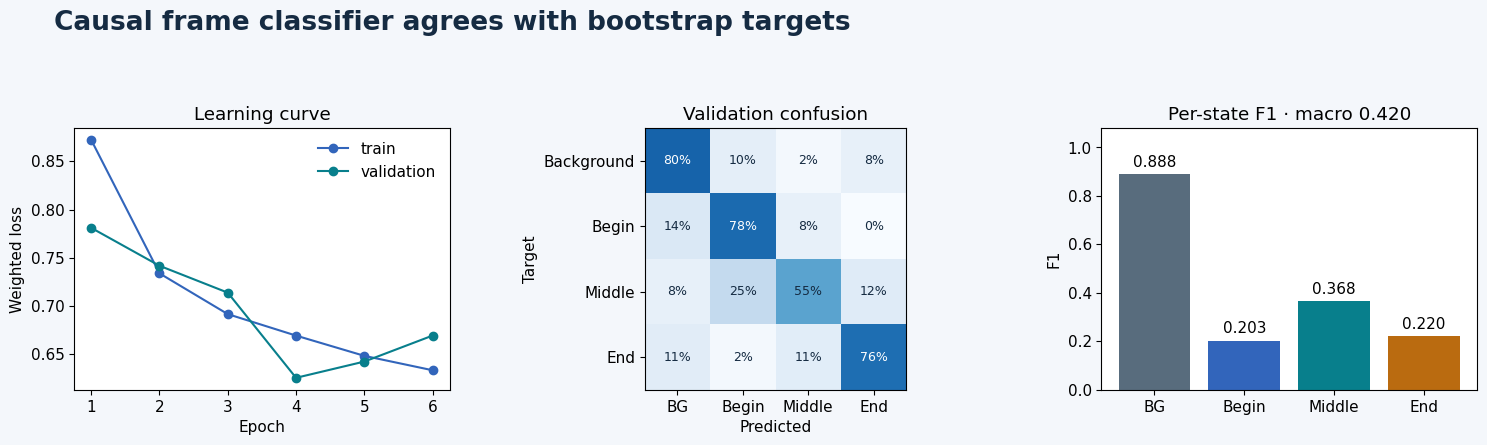

In [18]:
INK,MUTED,BLUE,TEAL,AMBER,RED="#152b42","#586c7d","#3265bb","#087f8c","#ba6b10","#bf4545"
plt.rcParams.update({"figure.facecolor":"#f4f7fb","axes.facecolor":"white","font.size":11})
fig,axes=plt.subplots(1,3,figsize=(15,4.6))
epochs=[h["epoch"] for h in history]; axes[0].plot(epochs,[h["train_loss"] for h in history],marker="o",label="train",color=BLUE); axes[0].plot(epochs,[h["validation_loss"] for h in history],marker="o",label="validation",color=TEAL); axes[0].set(xlabel="Epoch",ylabel="Weighted loss",title="Learning curve"); axes[0].legend(frameon=False)
row_normalized=confusion/np.maximum(confusion.sum(1,keepdims=True),1); image=axes[1].imshow(row_normalized,cmap="Blues",vmin=0,vmax=1); axes[1].set(xticks=range(4),xticklabels=["BG","Begin","Middle","End"],yticks=range(4),yticklabels=["Background","Begin","Middle","End"],xlabel="Predicted",ylabel="Target",title="Validation confusion")
for i in range(4):
    for j in range(4): axes[1].text(j,i,f"{row_normalized[i,j]:.0%}",ha="center",va="center",color="white" if row_normalized[i,j]>.55 else INK,fontsize=9)
bars=axes[2].bar(["BG","Begin","Middle","End"],f1,color=[MUTED,BLUE,TEAL,AMBER]); axes[2].bar_label(bars,fmt="%.3f",padding=3); axes[2].set(ylim=(0,1.08),ylabel="F1",title=f"Per-state F1 · macro {macro_f1:.3f}")
fig.suptitle("Causal frame classifier agrees with bootstrap targets",x=.04,ha="left",fontsize=19,weight="bold",color=INK)
fig.tight_layout(rect=(0,.02,1,.9)); figures=reports/"figures"; figures.mkdir(parents=True,exist_ok=True)
fig.savefig(figures/"11_dnn_training.png",dpi=170,bbox_inches="tight"); fig.savefig(figures/"11_dnn_training.svg",bbox_inches="tight"); plt.show()

## Interpretation and next action

- The network has no future context and can run one frame at a time.
- Validation measures agreement with bootstrap labels, not true phone boundaries.
- The test partition was not evaluated.
- Manual review remains explicitly incomplete.
- Frame predictions alone are not a trigger; isolated errors still need HMM sequence constraints.

Next: **12 · Viterbi realignment**. Convert DNN posteriors to prior-corrected state scores, decode only allowed HMM paths, replace training pseudo-labels with the best paths, and compare how much each boundary moved.